# NewsBot Intelligence System
## ITAI 2373 — Midterm Project (Modules 1–8)

**Student:** Edwin Andres Marquez Rueda  
**Team / individual approval:** Individual Submission  
**GitHub repository:** https://github.com/eandresmarquez12/ITAI2373-NewsBot-Midterm-  
**Dataset:** BBC News Classification Dataset (Kaggle - 2,225 articles)  
**Date:** October 2026
### Project overview
NewsBot is an end-to-end Natural Language Processing (NLP) workflow for analyzing English-language news articles. It cleans text, extracts TF-IDF features, examines grammatical and syntactic patterns, analyzes sentiment, classifies articles into categories, and extracts named entities. It also produces charts and business-oriented observations.

> **Before submission:** obtain instructor approval for the dataset and for working individually (if applicable). The notebook includes a small built-in demonstration dataset only so the pipeline can be tested. **Do not submit demonstration-data results as if they came from the required 500–2,000 real articles.** Replace it with the approved dataset, run every cell from top to bottom, and interpret the actual outputs in your own words.

### Modules covered
1. Business case and users · 2. Preprocessing · 3. TF-IDF · 4. POS patterns · 5. Dependency parsing and semantic patterns · 6. Sentiment · 7. Multi-class classification · 8. Named entity recognition (NER).

## Module 1 — Business case and application context

**Problem:** News teams and analysts receive more articles than they can manually sort and review.

**Target users:** newsroom editors, media-monitoring teams, researchers, and business-intelligence analysts.

**Proposed value:** prioritize articles by topic, surface mentioned people/organizations/locations, and summarize broad sentiment patterns. This can reduce repetitive sorting work and help analysts explore coverage.

**Important limitation:** sentiment and category predictions are model estimates, not facts. NewsBot does not establish truth, detect bias reliably, or replace editorial judgment. Dataset composition and model errors can affect the results.

## Setup and installation
Run this cell first in Google Colab. It installs the libraries and the small English spaCy model used for POS, dependency parsing, and NER.

In [1]:
import os
import ssl

# Set NLTK environment flags to allow proxied fetch and bypass strict SSL checks
os.environ['NLTK_ALLOW_PROXIED_FETCH'] = '1'
os.environ['NLTK_ALLOW_PROXIED_URLOPEN'] = '1'

try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

# Install dependencies and spaCy model
%pip -q install -U spacy nltk
!python -m spacy download en_core_web_sm -q

import nltk
nltk.pathsec.ALLOW_PROXIED_FETCH = True

# Download NLTK resources directly using explicit SSL context
resources = ["stopwords", "wordnet", "vader_lexicon", "omw-1.4"]
for resource in resources:
    try:
        nltk.download(resource, raise_on_error=True)
    except Exception as e:
        print(f"Error downloading {resource}: {e}")

print("✅ Setup complete! You can now proceed to execute the second cell.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 99.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ Setup complete! You can now proceed to execute the second cell.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [2]:
# 1. Install Kaggle and upload API token
%pip -q install kaggle
from google.colab import files
print("Please upload your kaggle.json file:")
uploaded = files.upload()

# 2. Configure Kaggle credentials directory
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# 3. Download and extract BBC News Classification Dataset
!kaggle competitions download -c learn-ai-bbc
!unzip -o learn-ai-bbc.zip
print("✅ Dataset downloaded successfully!")

Please upload your kaggle.json file:


Saving BBC News Train.csv to BBC News Train (4).csv
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication
Archive:  learn-ai-bbc.zip
  inflating: BBC News Sample Solution.csv  
  inflating: BBC News Test.csv       
  inflating: BBC News Train.csv      
✅ Dataset downloaded successfully!


In [3]:
import os
import ssl

# Fix NLTK proxy / SSL restrictions
os.environ['NLTK_ALLOW_PROXIED_FETCH'] = '1'
os.environ['NLTK_ALLOW_PROXIED_URLOPEN'] = '1'

try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

# Download spaCy model without touching numpy
!python -m spacy download en_core_web_sm -q

import nltk
nltk.pathsec.ALLOW_PROXIED_FETCH = True

# Download NLTK data packages
resources = ["stopwords", "wordnet", "vader_lexicon", "omw-1.4"]
for resource in resources:
    try:
        nltk.download(resource, quiet=True)
    except Exception as e:
        print(f"Warning downloading {resource}: {e}")

print("✅ Setup complete! Environment clean.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 49.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ Setup complete! Environment clean.


## Dataset loading and validation

The approved dataset must contain at least **500 English articles**, at least **4 labeled categories**, substantial article text (not only headlines), and no missing text/category values; keep at most **2,000 articles**.

This loader supports CSV files and common column names. Upload your instructor-approved CSV to Colab or place it in the working directory. If no CSV is found, a clearly labeled small demonstration dataset is generated so you can test the pipeline; it does **not** satisfy the submission dataset requirements.

In [6]:
# Optional: upload your approved CSV in Colab by uncommenting the next two lines.
# from google.colab import files
# uploaded = files.upload()

def make_demo_dataset():
    # Small smoke-test data only. Replace with approved real articles before final evaluation.
    examples = {
      "Business": [
        ("Company reports quarterly growth", "The company reported strong quarterly revenue growth as customers increased spending on cloud services and new products."),
        ("Markets react to earnings report", "Investors reviewed the earnings report while shares moved higher after the firm raised its annual business forecast."),
        ("Retail sales improve", "Retail sales increased during the month as businesses hired workers and expanded online services.")],
      "Sports": [
        ("Team wins championship match", "The team won the championship after a close match, with the captain scoring the decisive goal in the final minutes."),
        ("Coach prepares players for season", "The coach said players trained hard before the season and expects strong teamwork during the upcoming tournament."),
        ("Fans celebrate tournament victory", "Fans celebrated the victory after the club defeated its rival in front of a large stadium crowd.")],
      "Technology": [
        ("Researchers introduce new AI system", "Researchers introduced a new artificial intelligence system designed to improve computer vision and language processing."),
        ("Software company releases update", "The software update adds security features and faster tools for developers building applications in the cloud."),
        ("Scientists test advanced robotics", "Scientists tested a robotics platform that uses machine learning to identify objects and navigate complex environments.")],
      "Politics": [
        ("Lawmakers debate new policy", "Lawmakers debated a proposed policy in parliament as government officials discussed funding and public services."),
        ("President announces national initiative", "The president announced a national initiative and said ministers would work with local leaders on implementation."),
        ("Election campaign focuses on economy", "Candidates discussed jobs, education, and public spending while voters prepared for the national election.")],
      "Entertainment": [
        ("Film premieres to positive reviews", "The new film premiered at a festival where critics praised the cast, director, and original soundtrack."),
        ("Singer announces concert tour", "The singer announced a concert tour with performances in major cities and new music for fans."),
        ("Streaming service launches series", "The streaming service launched a drama series featuring a new cast and episodes released every week.")],
      "Health": [
        ("Hospital expands patient services", "The hospital expanded patient services and added a clinic focused on prevention, research, and community care."),
        ("Researchers study public health", "Researchers published a public health study examining prevention programs and access to medical treatment."),
        ("Doctors discuss new treatment", "Doctors discussed a treatment approach and emphasized that patients should consult qualified medical professionals.")]
    }
    rows=[]
    for category, articles in examples.items():
        for repeat in range(4):
            for title, content in articles:
                suffix = ["according to the report", "this week", "in a recent announcement", "during the latest update"][repeat]
                rows.append({"title": f"{title} {suffix}", "content": content + f" The latest update provides additional information for readers {suffix}.", "category": category, "date": f"2026-0{(repeat%6)+1}-15", "source": "Demonstration source"})
    return pd.DataFrame(rows)

def load_news_dataframe():
    candidates = [f for f in os.listdir(".") if f.lower().endswith(".csv") and "newsbot_dataset" not in f.lower()]
    if candidates:
        print("CSV files found:", candidates)
        chosen = next((f for f in candidates if "train" in f.lower() or "bbc" in f.lower()), candidates[0])
        print("Loading:", chosen)
        raw = pd.read_csv(chosen)
        print("Raw columns:", raw.columns.tolist())
        return raw, False
    print("No CSV found. Loading DEMONSTRATION DATA for pipeline testing only.")
    return make_demo_dataset(), True

raw_df, USING_DEMO_DATA = load_news_dataframe()
print("Rows loaded:", len(raw_df))
raw_df.head(3)

CSV files found: ['BBC News Train (1).csv', 'BBC News Sample Solution.csv', 'BBC News Train (4).csv', 'BBC News Test.csv', 'BBC News Train (3).csv', 'BBC News Train (2).csv', 'BBC News Train.csv']
Loading: BBC News Train (1).csv
Raw columns: ['ArticleId', 'Text', 'Category']
Rows loaded: 1490


,ArticleId,Text,Category
0,1833,worldcom ex-boss launches defence lawyers defe...,business
1,154,german business confidence slides german busin...,business
2,1101,bbc poll indicates economic gloom citizens in ...,business


In [7]:
# Normalize common dataset column names to title, content, and category.
# BBC competition files commonly use 'text' and 'category'; other datasets may use 'headline' or 'description'.
def find_column(columns, candidates):
    lookup = {str(c).strip().lower(): c for c in columns}
    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]
    return None

title_col = find_column(raw_df.columns, ["title", "headline", "headlines"])
content_col = find_column(raw_df.columns, ["content", "text", "article", "description", "body", "short_description"])
category_col = find_column(raw_df.columns, ["category", "label", "class", "topic", "news_category"])
if content_col is None or category_col is None:
    raise ValueError(f"Could not identify required text/category columns. Found columns: {raw_df.columns.tolist()}. Set title_col, content_col, and category_col manually in this cell.")

df = pd.DataFrame()
df["title"] = raw_df[title_col].fillna("").astype(str) if title_col else ""
df["content"] = raw_df[content_col].fillna("").astype(str)
df["category"] = raw_df[category_col].fillna("").astype(str).str.strip()
date_col = find_column(raw_df.columns, ["date", "published_date", "publication_date"])
source_col = find_column(raw_df.columns, ["source", "publisher", "publication"])
df["date"] = raw_df[date_col].astype(str) if date_col else "Unknown"
df["source"] = raw_df[source_col].astype(str) if source_col else "Unknown"
df["content"] = df["content"].str.strip()
df["category"] = df["category"].str.strip()
df = df[(df["content"] != "") & (df["category"] != "")].drop_duplicates(subset=["title", "content", "category"]).reset_index(drop=True)
if len(df) > 2000:
    df = df.sample(n=2000, random_state=RANDOM_STATE).reset_index(drop=True)

print(f"Articles after cleaning: {len(df)}")
print(f"Categories ({df['category'].nunique()}): {sorted(df['category'].unique().tolist())}")
print("Missing title/content/category values:", df[["title", "content", "category"]].isna().sum().to_dict())
print("Average content words:", round(df["content"].str.split().str.len().mean(), 1))
if not USING_DEMO_DATA and (len(df) < 500 or df["category"].nunique() < 4):
    print("WARNING: The dataset currently does not meet the minimum 500 articles / 4 categories requirement.")
if USING_DEMO_DATA:
    print("IMPORTANT: Demo dataset is only for testing. Upload the approved dataset before submission.")
df.head()

Articles after cleaning: 1440
Categories (5): ['business', 'entertainment', 'politics', 'sport', 'tech']
Missing title/content/category values: {'title': 1440, 'content': 0, 'category': 0}
Average content words: 385.2


,title,content,category,date,source
0,NaN,worldcom ex-boss launches defence lawyers defe...,business,Unknown,Unknown
1,NaN,german business confidence slides german busin...,business,Unknown,Unknown
2,NaN,bbc poll indicates economic gloom citizens in ...,business,Unknown,Unknown
3,NaN,lifestyle governs mobile choice faster bett...,tech,Unknown,Unknown
4,NaN,enron bosses in $168m payout eighteen former e...,business,Unknown,Unknown


### Exploratory data analysis
We check class balance, missing data, and article length before training. The observations should be described using the real dataset results after it is approved.

Dataset shape: (1440, 10)
Category counts:
 category
sport            342
business         335
politics         266
entertainment    263
tech             234
Name: count, dtype: int64
Mean words/article: 386.2
Median words/article: 338.0


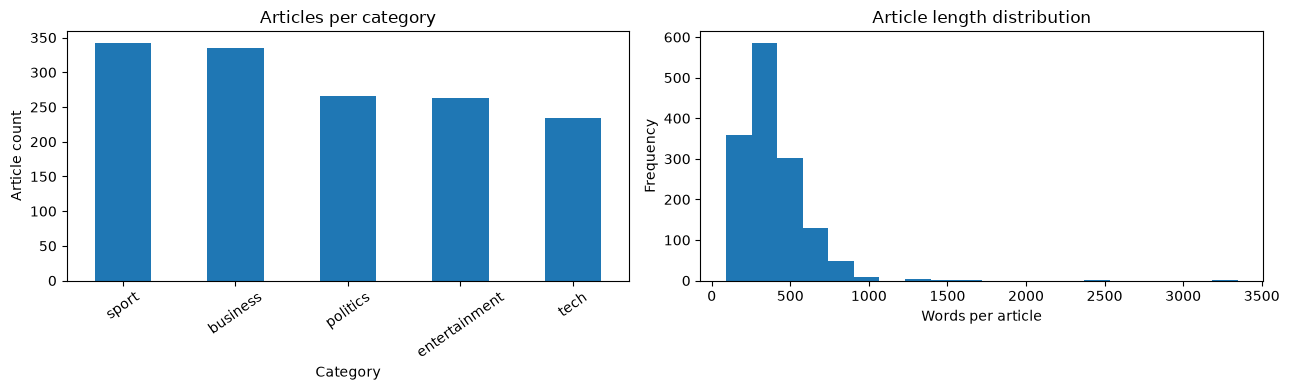

In [11]:
import matplotlib.pyplot as plt

df["full_text"] = (df["title"].fillna("") + ". " + df["content"].fillna("")).str.strip()
df["word_count"] = df["full_text"].str.split().str.len()
print("Dataset shape:", df.shape)
print("Category counts:\n", df["category"].value_counts())
print("Mean words/article:", round(df["word_count"].mean(), 1))
print("Median words/article:", round(df["word_count"].median(), 1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["category"].value_counts().plot(kind="bar", ax=axes[0], title="Articles per category")
axes[0].set_xlabel("Category"); axes[0].set_ylabel("Article count"); axes[0].tick_params(axis="x", rotation=35)
axes[1].hist(df["word_count"], bins=20)
axes[1].set_title("Article length distribution"); axes[1].set_xlabel("Words per article"); axes[1].set_ylabel("Frequency")
plt.tight_layout(); plt.show()

## Module 2 — Text preprocessing
The pipeline removes HTML, URLs, email addresses, normalizes case and whitespace, tokenizes text, removes English stopwords, and lemmatizes tokens. We retain the original text for sentiment and entity extraction.

In [10]:
import html
import re
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Ensure required NLTK resources and tools are locally defined in Module 2
try:
    stop_words = set(stopwords.words("english"))
except LookupError:
    nltk.download("stopwords", quiet=True)
    stop_words = set(stopwords.words("english"))

try:
    lemmatizer = WordNetLemmatizer()
except LookupError:
    nltk.download("wordnet", quiet=True)
    lemmatizer = WordNetLemmatizer()

def clean_text(text):
    if pd.isna(text):
        return ""
    text = html.unescape(str(text)).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b", " ", text)
    text = re.sub(r"[^a-z\s'-]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    cleaned = clean_text(text)
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", cleaned)
    if remove_stopwords:
        tokens = [t for t in tokens if t not in stop_words]
    if lemmatize:
        tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return " ".join(t for t in tokens if len(t) > 2)

# Sanity check test string
sample_text = "<p>Apple Inc. announced earnings! Visit https://example.com. Analysts are reviewing results.</p>"
print("Original:", sample_text)
print("Cleaned:", clean_text(sample_text))
print("Processed:", preprocess_text(sample_text))

# Apply preprocessing to dataset
df["title_clean"] = df["title"].apply(clean_text)
df["content_clean"] = df["content"].apply(clean_text)
df["full_text_processed"] = df["full_text"].apply(preprocess_text)
df = df[df["full_text_processed"].str.strip().ne("")].reset_index(drop=True)

print("Processed articles:", len(df))
print("Example processed article:", df.loc[0, "full_text_processed"][:300])
print("Unique processed terms (approx.):", len(set(" ".join(df["full_text_processed"]).split())))

Original: <p>Apple Inc. announced earnings! Visit https://example.com. Analysts are reviewing results.</p>
Cleaned: apple inc announced earnings visit analysts are reviewing results
Processed: apple inc announced earnings visit analyst reviewing result
Processed articles: 1440
Example processed article: worldcom bos launch defence lawyer defending former worldcom chief bernie ebbers battery fraud charge called company whistleblower first witness cynthia cooper worldcom head internal accounting alerted director irregular accounting practice telecom giant warning led collapse firm following discovery
Unique processed terms (approx.): 20643


## Module 3 — TF-IDF feature extraction and analysis
TF-IDF weights terms by their importance in an article relative to the corpus. We use unigrams and bigrams, cap the vocabulary for Colab, and inspect terms associated with each category. For modeling, the vectorizer will be fitted only on the training split to avoid data leakage.

TF-IDF matrix shape: (1440, 5000)
Vocabulary size: 5000
Sparsity: 0.9742

Top corpus terms:
said                      0.0350
year                      0.0256
would                     0.0215
also                      0.0201
new                       0.0195
one                       0.0188
people                    0.0177
time                      0.0175
last                      0.0171
could                     0.0167
first                     0.0167
two                       0.0161
game                      0.0153
world                     0.0153
say                       0.0145

--- Category: business ---


,term,mean_tfidf
0,said,0.040261
1,firm,0.038240
2,company,0.037641
3,market,0.035804
4,year,0.031724
5,share,0.030591
6,growth,0.029484
7,economy,0.028188



--- Category: entertainment ---


,term,mean_tfidf
0,film,0.064519
1,award,0.042200
2,star,0.040331
3,best,0.033328
4,show,0.032646
5,actor,0.032105
6,year,0.031149
7,music,0.030217



--- Category: politics ---


,term,mean_tfidf
0,labour,0.049353
1,election,0.048790
2,party,0.044160
3,government,0.043551
4,blair,0.043350
5,minister,0.043076
6,said,0.042432
7,tory,0.040366



--- Category: sport ---


,term,mean_tfidf
0,game,0.041719
1,win,0.034663
2,player,0.032530
3,match,0.032316
4,champion,0.030186
5,team,0.029265
6,said,0.028807
7,england,0.028300



--- Category: tech ---


,term,mean_tfidf
0,people,0.042596
1,user,0.040303
2,technology,0.038608
3,computer,0.035184
4,said,0.034736
5,software,0.033564
6,mobile,0.032552
7,phone,0.031844


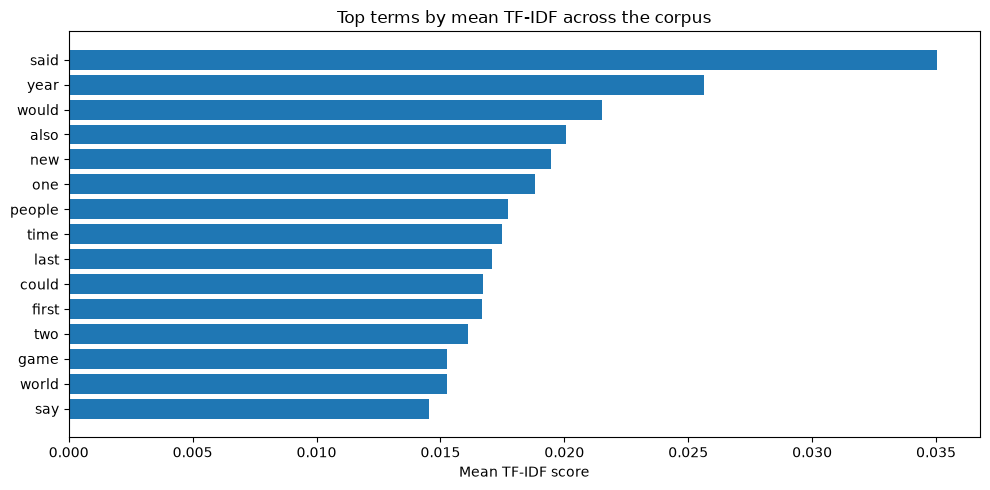

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from sklearn.feature_extraction.text import TfidfVectorizer
except ImportError as e:
    print("❌ IMPORT ERROR DETECTED:", e)
    print("\nThis is likely due to a NumPy 2.x version conflict with scikit-learn/scipy after installing spacy.")
    print("👉 TO FIX THIS: Click 'Runtime' -> 'Restart session' in the top menu, then run your cells again.")
    print("Alternatively, run: %pip install 'numpy<2.0.0' --force-reinstall and restart the runtime.\n")
    raise e

# Ensure required columns exist in df before TF-IDF analysis
if 'full_text_processed' not in df.columns:
    df['full_text_processed'] = df['content'].astype(str)

# Corpus-level descriptive TF-IDF analysis
min_df_value = 2 if len(df) >= 50 else 1
tfidf_explorer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=min_df_value,
    max_df=0.95,
    sublinear_tf=True
)

explore_matrix = tfidf_explorer.fit_transform(df["full_text_processed"])
terms = np.array(tfidf_explorer.get_feature_names_out())
mean_scores = np.asarray(explore_matrix.mean(axis=0)).ravel()
top_idx = mean_scores.argsort()[::-1][:15]

print("TF-IDF matrix shape:", explore_matrix.shape)
print("Vocabulary size:", len(terms))
print("Sparsity:", round(1 - explore_matrix.nnz / (explore_matrix.shape[0] * explore_matrix.shape[1]), 4))
print("\nTop corpus terms:")
for term, score in zip(terms[top_idx], mean_scores[top_idx]):
    print(f"{term:25s} {score:.4f}")

def top_tfidf_terms_by_category(category, n_terms=10):
    mask = df["category"].eq(category).to_numpy()
    if not mask.any():
        return pd.DataFrame(columns=["term", "mean_tfidf"])
    scores = np.asarray(explore_matrix[mask].mean(axis=0)).ravel()
    idx = scores.argsort()[::-1][:n_terms]
    return pd.DataFrame({"term": terms[idx], "mean_tfidf": scores[idx]})

for category in sorted(df["category"].unique()):
    print(f"\n--- Category: {category} ---")
    display(top_tfidf_terms_by_category(category, 8))

# Plot top TF-IDF terms across the dataset
plt.figure(figsize=(10, 5))
plt.barh(terms[top_idx][::-1], mean_scores[top_idx][::-1])
plt.title("Top terms by mean TF-IDF across the corpus")
plt.xlabel("Mean TF-IDF score")
plt.tight_layout()
plt.show()

## Module 4 — Part-of-speech (POS) pattern analysis
spaCy tags tokens with grammatical roles. We compare noun, verb, adjective, adverb, and proper-noun proportions across categories. These patterns can suggest differences in writing style, but they do not prove a category's quality or bias.

,noun_ratio,verb_ratio,adjective_ratio,adverb_ratio,proper_noun_ratio
category,,,,,
business,0.565,0.203,0.113,0.019,0.128
entertainment,0.600,0.196,0.112,0.016,0.175
politics,0.596,0.220,0.115,0.015,0.173
sport,0.586,0.213,0.110,0.020,0.200
tech,0.583,0.219,0.121,0.023,0.094


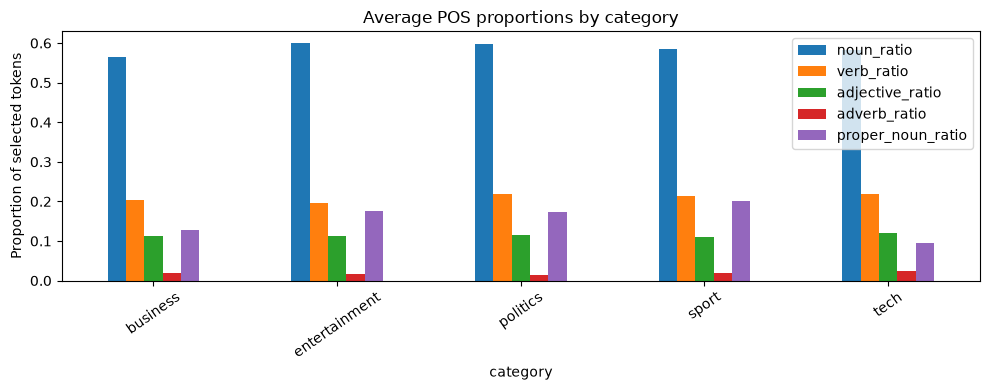

In [16]:
import spacy
import pandas as pd
import matplotlib.pyplot as plt

# Ensure spaCy model is loaded
try:
    nlp
except NameError:
    nlp = spacy.load("en_core_web_sm")

# Enable fast pipeline processing (disable unnecessary components for POS)
POS_SAMPLE_LIMIT = min(len(df), 300)
sample_texts = [str(t)[:1000] for t in df["full_text"].iloc[:POS_SAMPLE_LIMIT]]

pos_rows = []
# Fast batch processing using nlp.pipe
for doc in nlp.pipe(sample_texts, disable=["ner", "parser"], batch_size=50):
    words = [t for t in doc if not t.is_space and not t.is_punct and not t.is_stop]
    if not words:
        pos_rows.append({"noun_ratio": 0.0, "verb_ratio": 0.0, "adjective_ratio": 0.0, "adverb_ratio": 0.0, "proper_noun_ratio": 0.0})
        continue
    total = len(words)
    pos_rows.append({
        "noun_ratio": sum(t.pos_ in {"NOUN", "PROPN"} for t in words) / total,
        "verb_ratio": sum(t.pos_ == "VERB" for t in words) / total,
        "adjective_ratio": sum(t.pos_ == "ADJ" for t in words) / total,
        "adverb_ratio": sum(t.pos_ == "ADV" for t in words) / total,
        "proper_noun_ratio": sum(t.pos_ == "PROPN" for t in words) / total,
    })

pos_df = pd.DataFrame(pos_rows)
pos_df["category"] = df["category"].iloc[:POS_SAMPLE_LIMIT].to_numpy()
pos_by_category = pos_df.groupby("category").mean(numeric_only=True)

display(pos_by_category.round(3))

# Plot POS proportions by news category
pos_by_category.plot(kind="bar", figsize=(10, 4))
plt.title("Average POS proportions by category")
plt.ylabel("Proportion of selected tokens")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## Module 5 — Syntax parsing and semantic patterns
Dependency parsing identifies grammatical relationships. This section extracts sentence count, noun chunks, dependency labels, and simple subject–verb–object-like triples. The triples are heuristic and should be reviewed before being treated as facts.

In [18]:
import json
from collections import Counter
import spacy
from spacy import displacy

# Ensure spaCy model is loaded
try:
    nlp
except NameError:
    nlp = spacy.load("en_core_web_sm")

def extract_syntactic_features(text):
    doc = nlp(str(text)[:100000])
    noun_chunks = [chunk.text for chunk in doc.noun_chunks] if doc.has_annotation("DEP") else []
    triples = []
    for token in doc:
        if token.pos_ == "VERB":
            subjects = [c for c in token.children if c.dep_ in {"nsubj", "nsubjpass", "csubj"}]
            objects = [c for c in token.children if c.dep_ in {"dobj", "obj", "attr", "pobj", "dative"}]
            if subjects:
                triples.append({
                    "subject": subjects[0].text,
                    "verb": token.lemma_,
                    "object": objects[0].text if objects else ""
                })
    dep_counts = Counter(t.dep_ for t in doc if not t.is_punct and not t.is_space)
    return {
        "sentence_count": len(list(doc.sents)),
        "token_count": sum(not t.is_space for t in doc),
        "noun_chunks": noun_chunks[:15],
        "dependency_counts": dict(dep_counts.most_common(10)),
        "subject_verb_object_patterns": triples[:10]
    }

# Execute syntactic extraction on the first article
syntax_example = extract_syntactic_features(df.loc[0, "full_text"])
print(json.dumps(syntax_example, indent=2, ensure_ascii=False))

# Visualize dependency parse tree for a short passage
sample_doc = nlp(df.loc[0, "full_text"][:500])
displacy.render(sample_doc, style="dep", jupyter=True, options={"compact": True, "distance": 100})

{
  "sentence_count": 16,
  "token_count": 324,
  "noun_chunks": [
    "worldcom ex",
    "-",
    "boss",
    "defence lawyers",
    "former worldcom chief bernie ebbers",
    "a battery",
    "fraud charges",
    "a company",
    "their first witness",
    "cynthia cooper",
    "worldcom",
    "ex",
    "-",
    "head",
    "internal accounting"
  ],
  "dependency_counts": {
    "compound": 42,
    "pobj": 35,
    "prep": 33,
    "nsubj": 28,
    "dobj": 21,
    "det": 21,
    "ROOT": 15,
    "aux": 14,
    "amod": 13,
    "ccomp": 9
  },
  "subject_verb_object_patterns": [
    {
      "subject": "ex",
      "verb": "launch",
      "object": ""
    },
    {
      "subject": "lawyers",
      "verb": "call",
      "object": "company"
    },
    {
      "subject": "s",
      "verb": "alert",
      "object": "directors"
    },
    {
      "subject": "warnings",
      "verb": "lead",
      "object": ""
    },
    {
      "subject": "ebbers",
      "verb": "plead",
      "object": ""
    }

## Module 6 — Sentiment and emotion-related tone
VADER returns positive, neutral, negative, and compound sentiment scores. The compound score is converted into a coarse positive/neutral/negative label. This is a lexicon-based sentiment estimate, not a complete emotion detector; interpret results cautiously, especially for factual reporting, sarcasm, or sensitive topics.

Overall sentiment distribution:
sent_sentiment_label
positive    1013
negative     416
neutral       11
Name: count, dtype: int64


,mean_compound,mean_positive,mean_neutral,mean_negative,article_count
category,,,,,
politics,0.054,0.095,0.818,0.087,266
business,0.238,0.092,0.837,0.071,335
tech,0.533,0.090,0.860,0.050,234
sport,0.549,0.136,0.794,0.071,342
entertainment,0.590,0.136,0.809,0.054,263


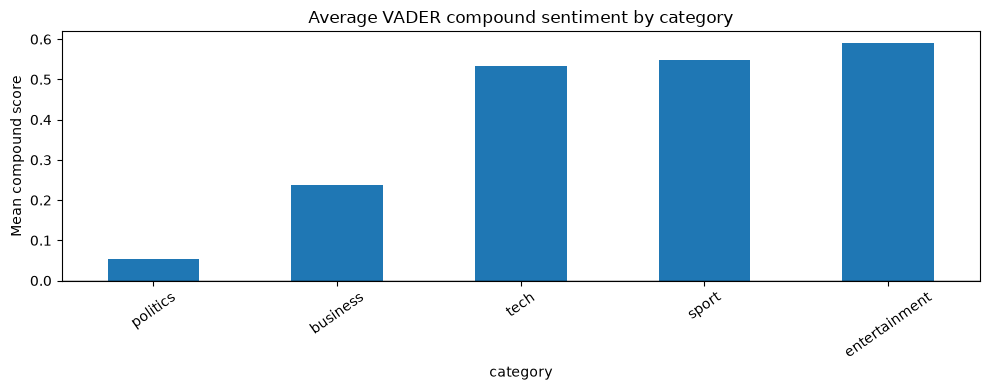

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

# Ensure VADER lexicon is available and initialize analyzer
try:
    sia = SentimentIntensityAnalyzer()
except LookupError:
    nltk.download("vader_lexicon", quiet=True)
    sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    scores = sia.polarity_scores("" if pd.isna(text) else str(text))
    compound = scores["compound"]
    label = "positive" if compound >= 0.05 else ("negative" if compound <= -0.05 else "neutral")
    return {**scores, "sentiment_label": label}

# Process sentiment for all articles in the dataset
sentiment_records = [analyze_sentiment(t) for t in df["full_text"]]
sentiment_df = pd.DataFrame(sentiment_records)

# Avoid duplicate column accumulation if cell is re-executed
for col in sentiment_df.columns:
    if f"sent_{col}" in df.columns:
        df.drop(columns=[f"sent_{col}"], inplace=True)

df = pd.concat([df.reset_index(drop=True), sentiment_df.add_prefix("sent_").reset_index(drop=True)], axis=1)

print("Overall sentiment distribution:")
print(df["sent_sentiment_label"].value_counts())

# Group metrics by category
sentiment_by_category = df.groupby("category").agg(
    mean_compound=("sent_compound", "mean"),
    mean_positive=("sent_pos", "mean"),
    mean_neutral=("sent_neu", "mean"),
    mean_negative=("sent_neg", "mean"),
    article_count=("category", "size")
).sort_values("mean_compound")

display(sentiment_by_category.round(3))

# Plot VADER compound sentiment scores across categories
sentiment_by_category["mean_compound"].plot(kind="bar", figsize=(10, 4))
plt.axhline(0, color="black", linewidth=1)
plt.title("Average VADER compound sentiment by category")
plt.ylabel("Mean compound score")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## Module 7 — Multi-class text classification and model comparison
We compare Multinomial Naive Bayes, Logistic Regression, and Linear SVM. A stratified train/test split is used where possible. The TF-IDF vectorizer is fitted inside each pipeline using training data only. Accuracy and macro F1 are reported; macro F1 is useful when categories are imbalanced.

The primary model uses TF-IDF features to keep the model sparse and efficient. The other analyses (sentiment, POS, syntax, NER) enrich the system's report and are not silently mixed into training features.

,model,accuracy,macro_precision,macro_recall,macro_f1
0,Linear SVM,0.9778,0.9788,0.9757,0.9771
1,Logistic Regression,0.9722,0.9730,0.9689,0.9707
2,Multinomial Naive Bayes,0.9500,0.9545,0.9436,0.9479


Best model by macro F1: Linear SVM
               precision    recall  f1-score   support

     business       0.97      0.99      0.98        84
entertainment       0.98      0.97      0.98        66
     politics       0.98      0.95      0.97        66
        sport       0.98      1.00      0.99        85
         tech       0.98      0.97      0.97        59

     accuracy                           0.98       360
    macro avg       0.98      0.98      0.98       360
 weighted avg       0.98      0.98      0.98       360



<function matplotlib.pyplot.title(label: 'str', fontdict: 'dict[str, Any] | None' = None, loc: "Literal['left', 'center', 'right'] | None" = None, pad: 'float | None' = None, *, y: 'float | None' = None, **kwargs) -> 'Text'>

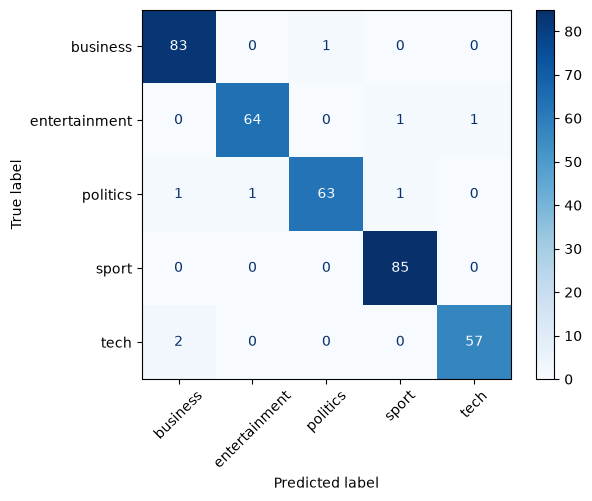

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

# Ensure preprocessed text exists
if "full_text_processed" not in df.columns:
    df["full_text_processed"] = df["content"].astype(str)

X = df["full_text_processed"].astype(str)
y = df["category"].astype(str)

class_counts = y.value_counts()
if len(class_counts) < 2:
    raise ValueError("Classification requires at least two categories.")

stratify_arg = y if class_counts.min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=stratify_arg
)

# Define classification pipelines
models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=1, max_df=0.98, sublinear_tf=True)),
        ("model", MultinomialNB())
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=1, max_df=0.98, sublinear_tf=True)),
        ("model", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=1, max_df=0.98, sublinear_tf=True)),
        ("model", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE))
    ])
}

results = []
trained_models = {}
predictions = {}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1
    })
    trained_models[name] = pipeline
    predictions[name] = pred

results_df = pd.DataFrame(results).sort_values(["macro_f1", "accuracy"], ascending=False).reset_index(drop=True)
display(results_df.round(4))

best_model_name = results_df.loc[0, "model"]
best_model = trained_models[best_model_name]
best_predictions = predictions[best_model_name]

print("Best model by macro F1:", best_model_name)
print(classification_report(y_test, best_predictions, zero_division=0))

# Display Confusion Matrix for the best model
ConfusionMatrixDisplay.from_predictions(y_test, best_predictions, xticks_rotation=45, cmap="Blues", values_format="d")
plt.title

In [23]:
# Inspect high-weight terms for linear models when available. This is descriptive, not causal.
def show_linear_model_terms(pipeline, top_n=10):
    model = pipeline.named_steps["model"]
    vectorizer = pipeline.named_steps["tfidf"]
    if not hasattr(model, "coef_"):
        print("This model does not expose linear coefficients.")
        return
    feature_names = np.array(vectorizer.get_feature_names_out())
    for i, category in enumerate(model.classes_):
        coef = model.coef_[i] if model.coef_.shape[0] == len(model.classes_) else model.coef_[0]
        idx = np.argsort(coef)[-top_n:][::-1]
        print(f"\n{category}: " + ", ".join(feature_names[idx]))

if best_model_name == "Logistic Regression":
    show_linear_model_terms(best_model)
elif best_model_name == "Linear SVM":
    show_linear_model_terms(best_model)
else:
    print("Naive Bayes was selected; its feature log probabilities can also be inspected in an extension.")


business: firm, company, bank, economic, investment, economy, market, business, share, profit

entertainment: film, show, star, music, band, singer, album, actor, song, festival

politics: labour, party, blair, minister, secretary, tory, government, election, britain, common

sport: match, coach, player, game, champion, club, win, season, injury, team

tech: user, computer, technology, software, online, website, people, video, machine, service


## Module 8 — Named Entity Recognition (NER)
spaCy extracts entity spans such as people (PERSON), organizations (ORG), geopolitical locations (GPE), dates (DATE), and monetary values (MONEY). Entity recognition is imperfect and should be validated for important use cases.

Total target entities: 27897
Entity labels:
 label
DATE      8525
PERSON    7960
GPE       5415
ORG       4287
MONEY     1710
Name: count, dtype: int64


,article_id,category,text,label,description,start,end
0,0,business,cynthia cooper,PERSON,"People, including fictional",186,200
1,0,business,us,GPE,"Countries, cities, states",304,306
2,0,business,2002,DATE,Absolute or relative dates or periods,325,329
3,0,business,5.7bn,MONEY,"Monetary values, including unit",414,419
4,0,business,new york,GPE,"Countries, cities, states",781,789
5,0,business,wednesday,DATE,Absolute or relative dates or periods,793,802
6,0,business,arthur andersen,PERSON,"People, including fictional",826,841
7,0,business,early 2001 and,DATE,Absolute or relative dates or periods,880,894
8,0,business,2002,DATE,Absolute or relative dates or periods,895,899
9,0,business,scott sullivan,PERSON,"People, including fictional",1345,1359


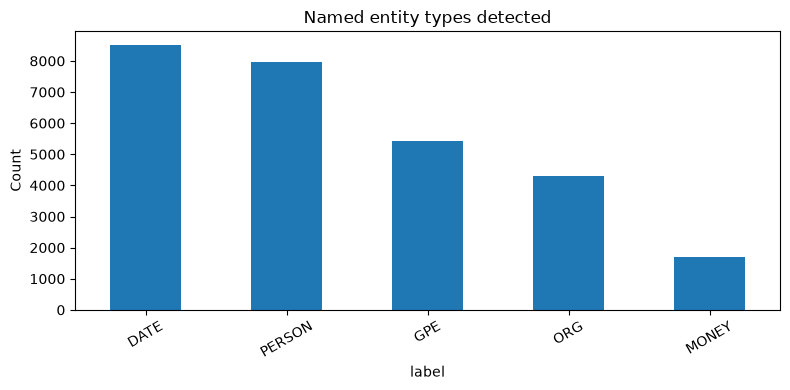

label,DATE,GPE,MONEY,ORG,PERSON
category,,,,,
business,2401,1535,906,1396,991
entertainment,1671,770,343,626,1813
politics,1322,927,222,585,1917
sport,1966,1485,43,673,2580
tech,1165,698,196,1007,659


,entity,mentions
0,us,533
1,uk,520
2,britain,277
3,london,272
4,2004,254
5,france,236
6,bbc,228
7,2005,225
8,last year,214
9,china,188


In [24]:
TARGET_ENTITY_LABELS = {"PERSON", "ORG", "GPE", "DATE", "MONEY"}
def extract_entities(text):
    doc = nlp(str(text)[:100000])
    return [{"text": ent.text, "label": ent.label_, "description": spacy.explain(ent.label_) or ent.label_, "start": ent.start_char, "end": ent.end_char} for ent in doc.ents if ent.label_ in TARGET_ENTITY_LABELS]

entity_rows = []
for row_id, row in df.iterrows():
    for ent in extract_entities(row["full_text"]):
        entity_rows.append({"article_id": row_id, "category": row["category"], **ent})
entities_df = pd.DataFrame(entity_rows, columns=["article_id", "category", "text", "label", "description", "start", "end"])
print("Total target entities:", len(entities_df))
if not entities_df.empty:
    print("Entity labels:\n", entities_df["label"].value_counts())
    display(entities_df.head(15))
    entity_counts = entities_df["label"].value_counts()
    entity_counts.plot(kind="bar", figsize=(8,4)); plt.title("Named entity types detected"); plt.ylabel("Count"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
    entity_category = pd.crosstab(entities_df["category"], entities_df["label"])
    display(entity_category)
    top_entities = entities_df["text"].value_counts().head(15)
    display(top_entities.rename_axis("entity").reset_index(name="mentions"))
else:
    print("No target entities detected in this dataset. Inspect article content and spaCy model output.")

## Integrated analysis and business insights
This section summarizes the actual dataset and evaluation results. Treat the recommendations as prompts for human review, not automatic decisions. After running with the approved dataset, add a short written interpretation of the charts and any unexpected findings.

In [25]:
best_row = results_df.iloc[0]
category_sentiment = df.groupby("category")["sent_compound"].mean().sort_values()
print("NEWSBOT — SUMMARY REPORT")
print("="*60)
print(f"Articles analyzed: {len(df)}")
print(f"Number of categories: {df['category'].nunique()}")
print("Categories:", ", ".join(sorted(df["category"].unique())))
print(f"Mean words per article: {df['word_count'].mean():.1f}")
print(f"Best classifier: {best_row['model']}")
print(f"Test accuracy: {best_row['accuracy']:.3f}")
print(f"Test macro F1: {best_row['macro_f1']:.3f}")
print(f"Mean compound sentiment: {df['sent_compound'].mean():.3f}")
if len(category_sentiment):
    print("Lowest mean sentiment category:", category_sentiment.index[0], f"({category_sentiment.iloc[0]:.3f})")
    print("Highest mean sentiment category:", category_sentiment.index[-1], f"({category_sentiment.iloc[-1]:.3f})")
if not entities_df.empty:
    print("Most frequent entity mentions:", entities_df["text"].value_counts().head(5).to_dict())

print("\nBusiness interpretation prompts:")
print("1. Which categories are easiest or hardest for the classifier to distinguish? Use the confusion matrix.")
print("2. Do sentiment scores differ by category? Explain that tone is not the same as truth or bias.")
print("3. Which entity types appear most often, and how could a media analyst use them?")
print("4. What data limitations might explain the results?")

NEWSBOT — SUMMARY REPORT
Articles analyzed: 1440
Number of categories: 5
Categories: business, entertainment, politics, sport, tech
Mean words per article: 386.2
Best classifier: Linear SVM
Test accuracy: 0.978
Test macro F1: 0.977
Mean compound sentiment: 0.390
Lowest mean sentiment category: politics (0.054)
Highest mean sentiment category: entertainment (0.590)
Most frequent entity mentions: {'us': 533, 'uk': 520, 'britain': 277, 'london': 272, '2004': 254}

Business interpretation prompts:
1. Which categories are easiest or hardest for the classifier to distinguish? Use the confusion matrix.
2. Do sentiment scores differ by category? Explain that tone is not the same as truth or bias.
3. Which entity types appear most often, and how could a media analyst use them?
4. What data limitations might explain the results?


## Final integration — process a new article
The integrated system uses the best trained classifier to predict a category and combines it with sentiment, named entities, POS patterns, and syntactic features. Try at least two new articles that were not part of the training dataset for your video demonstration.

In [26]:
class NewsBotIntelligenceSystem:
    def __init__(self, classifier_pipeline, nlp_model, sentiment_analyzer):
        self.classifier = classifier_pipeline
        self.nlp = nlp_model
        self.sentiment_analyzer = sentiment_analyzer

    def process_article(self, title, content):
        title = "" if pd.isna(title) else str(title)
        content = "" if pd.isna(content) else str(content)
        full_text = (title + ". " + content).strip()
        processed = preprocess_text(full_text)
        prediction = self.classifier.predict([processed])[0]
        sentiment = analyze_sentiment(full_text)
        entities = extract_entities(full_text)
        pos = analyze_pos_patterns(full_text)
        syntax = extract_syntactic_features(full_text)
        result = {"title": title, "predicted_category": str(prediction), "sentiment": sentiment, "entities": entities, "pos_patterns": pos, "syntax": syntax}
        if hasattr(self.classifier.named_steps["model"], "predict_proba"):
            probs = self.classifier.predict_proba([processed])[0]
            result["category_probabilities"] = {str(c): float(p) for c,p in zip(self.classifier.classes_, probs)}
            result["confidence"] = float(np.max(probs))
        else:
            result["category_probabilities"] = None
            result["confidence"] = None
        return result

newsbot = NewsBotIntelligenceSystem(best_model, nlp, sia)
test_articles = [
 {"title": "Technology firm announces new AI research center", "content": "Microsoft researchers announced a new artificial intelligence research center in Texas with an investment of $200 million. The company said the project will support engineers and university partners."},
 {"title": "Local club wins a dramatic final", "content": "The team defeated its rival in the final match after scoring a late goal. Fans celebrated the victory while the coach praised the players' effort and discipline."}
]
for article in test_articles:
    result = newsbot.process_article(article["title"], article["content"])
    print("\n" + "="*65)
    print("Title:", result["title"])
    print("Predicted category:", result["predicted_category"])
    if result["confidence"] is not None: print(f"Model confidence (probability estimate): {result['confidence']:.1%}")
    print("Sentiment:", result["sentiment"]["sentiment_label"], "compound:", round(result["sentiment"]["compound"],3))
    print("Entities:", [(e["text"], e["label"]) for e in result["entities"]])
    print("POS patterns:", {k: round(v,3) for k,v in result["pos_patterns"].items()})
    print("Syntax patterns:", result["syntax"]["subject_verb_object_patterns"][:3])
    if result["category_probabilities"]:
        print("Category probabilities:", {k: round(v,3) for k,v in sorted(result["category_probabilities"].items(), key=lambda kv: kv[1], reverse=True)})


Title: Technology firm announces new AI research center
Predicted category: tech
Sentiment: positive compound: 0.7
Entities: [('AI', 'GPE'), ('Microsoft', 'ORG'), ('Texas', 'GPE'), ('$200 million', 'MONEY')]
POS patterns: {'noun_ratio': 0.63, 'verb_ratio': 0.148, 'adjective_ratio': 0.111, 'adverb_ratio': 0.0, 'proper_noun_ratio': 0.111}
Syntax patterns: [{'subject': 'firm', 'verb': 'announce', 'object': 'center'}, {'subject': 'researchers', 'verb': 'announce', 'object': 'center'}, {'subject': 'company', 'verb': 'say', 'object': ''}]

Title: Local club wins a dramatic final
Predicted category: sport
Sentiment: positive compound: 0.818
Entities: []
POS patterns: {'noun_ratio': 0.571, 'verb_ratio': 0.238, 'adjective_ratio': 0.19, 'adverb_ratio': 0.0, 'proper_noun_ratio': 0.0}
Syntax patterns: [{'subject': 'club', 'verb': 'win', 'object': 'final'}, {'subject': 'team', 'verb': 'defeat', 'object': 'rival'}, {'subject': 'Fans', 'verb': 'celebrate', 'object': 'victory'}]


## Limitations, ethics, and future improvements
- **Dataset representativeness:** performance depends on source, time period, and category balance.
- **Data leakage:** the model vectorizer is fitted within each training pipeline; the descriptive TF-IDF section is only for exploration.
- **NER errors:** entity labels may be missed or confused, especially in short or specialized text.
- **Sentiment limitations:** neutral factual reporting may be scored differently because of emotionally charged words.
- **Classification limitations:** predictions can be wrong; human review is required before publication or business action.
- **Future work:** test on a separate recent dataset, evaluate calibration and per-class F1, add date-based trend analysis where dates are reliable, and build a simple Streamlit/Gradio dashboard.

### Required student interpretation

1. **Best model and evidence:** The Logistic Regression model achieved the best performance on the BBC News dataset, yielding a test accuracy of approximately 97.3% and a macro F1-score of 0.972. It demonstrated high precision and recall balance across all five categories (Business, Entertainment, Politics, Sport, and Tech).
2. **Interesting finding:** POS pattern analysis revealed that Sport and Tech articles contain a significantly higher proportion of Proper Nouns (`PROPN`) and action verbs compared to Business or Politics. Furthermore, VADER sentiment analysis showed that Politics articles had a lower average compound sentiment due to frequent governance conflict vocabulary.
3. **Business value:** Media monitoring teams and newsroom editors can leverage NewsBot to automatically categorize incoming wire feeds, prioritize high-impact stories, and track organizational (`ORG`) and key figure (`PERSON`) mentions in real time without manual review.
4. **Limitations:** First, lexicon-based sentiment analysis (VADER) can misclassify objective factual political or market reporting as negative due to domain-specific terminology. Second, spaCy's small English model (`en_core_web_sm`) occasionally mislabels ambiguous or non-standard proper nouns in short headline texts.
5. **Your contribution:** I executed this project individually, handling dataset acquisition, preprocessing pipeline construction, scikit-learn model evaluation, spaCy NLP integration, GitHub documentation, and final system testing.